# Confirmación y cierre: advección periódica

**Objetivo.** Comprobar si el buen resultado de `k=8` observado con la condición Fourier de cuatro armónicos se mantiene en una condición inicial periódica nueva, sin volver a buscar `k` con los datos de prueba.

La nueva condición tiene seis armónicos:

\[u_0(x)=\sin(\pi x)+0.75\cos(2\pi x)+0.5\sin(3\pi x)+0.35\cos(4\pi x)+0.25\sin(5\pi x)+0.18\cos(6\pi x),\quad u(x,t)=u_0(x-ct).\]

`k=8` se fijó antes de esta corrida por el resultado anterior. Se compara con la PINN base y con la selección PCA automática al 99%.

## Protocolo

- Diez semillas (2041–2050), las mismas particiones, muestras de condición inicial, minibatches y puntos de colocación PDE dentro de cada semilla.
- Presupuesto fijo de 5000 pasos y evaluación cada 100 pasos.
- PCA se ajusta únicamente con snapshots de los tiempos de entrenamiento. La regla al 99% eligió `k=6` en las diez semillas, con retención media de 99,31%.
- Las métricas de prueba se calculan al final y no se usan para cambiar `k` ni otros hiperparámetros.
- Se registran error de solución, residuo PDE, defecto periódico y tiempo de pipeline; la compilación JAX se mide aparte.

In [ ]:
from pathlib import Path
import json
from IPython.display import display, HTML, SVG

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RUN_DIR = ROOT / "results/advection/base_vs_pca/six_harmonic_confirmation_10_seeds_5k_v1"
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))


def html_table(headers, rows):
    head = "".join(f"<th>{h}</th>" for h in headers)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    return f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"


def stat(name, metric, digits=4):
    v = RESULT["summary"][name][metric]
    return f"{v['mean']:.{digits}g} ± {v['std']:.{digits}g}"


## Resultados en prueba

Media ± desviación estándar entre semillas.

In [1]:
ORDER = ["PINN base", "PCA AD 99%", "PCA AD k=8"]
rows = []
for name in ORDER:
    s = RESULT["summary"][name]
    k = "—" if s["k"] is None else f"{s['k']['mean']:.0f}"
    variance = "—" if s["retained_variance"] is None else f"{100*s['retained_variance']['mean']:.4f}% ± {100*s['retained_variance']['std']:.3g}%"
    rows.append([name, k, variance, stat(name, "test_relative_l2"), stat(name, "test_pde_residual_rms"), stat(name, "test_periodic_boundary_rms", 3), stat(name, "pipeline_seconds", 3)])
display(HTML(html_table(["Modelo", "k", "Varianza retenida", "Error L2 relativo (prueba)", "Residuo PDE RMS", "Defecto periódico RMS", "Pipeline (s)"], rows)))


Modelo,k,Varianza retenida,Error L2 relativo (prueba),Residuo PDE RMS,Defecto periódico RMS,Pipeline (s)
PINN base,—,—,0.05391 ± 0.006572,0.03716 ± 0.005959,0.0653 ± 0.0248,8.24 ± 0.279
PCA AD 99%,6,99.3084% ± 0.0563%,0.286 ± 0.03207,0.8401 ± 0.1019,2.49e-07 ± 3.08e-08,7.1 ± 0.2
PCA AD k=8,8,99.9927% ± 0.00118%,0.179 ± 0.01923,0.4415 ± 0.06805,2.71e-07 ± 2.51e-08,7.13 ± 0.316


## Comparación pareada con la PINN base

`Δ` es PCA menos PINN base dentro de cada semilla; un valor negativo favorece a PCA.

In [1]:
rows = []
for name in ORDER[1:]:
    m = RESULT["paired_differences_PCA_minus_base"][name]
    e, p, t = (m[key] for key in ("test_relative_l2", "test_pde_residual_rms", "pipeline_seconds"))
    rows.append([name, f"{e['PCA_minus_base_mean']:+.5f}", f"{e['PCA_better_count']}/10", f"{p['PCA_minus_base_mean']:+.5f}", f"{p['PCA_better_count']}/10", f"{t['PCA_minus_base_mean']:+.3f}", f"{t['PCA_better_count']}/10"])
display(HTML(html_table(["Modelo", "Δ error L2 vs base", "Semillas mejor error", "Δ residuo PDE", "Semillas mejor residuo", "Δ pipeline (s)", "Semillas más rápidas"], rows)))


Modelo,Δ error L2 vs base,Semillas mejor error,Δ residuo PDE,Semillas mejor residuo,Δ pipeline (s),Semillas más rápidas
PCA AD 99%,+0.23207,0/10,+0.80291,0/10,-1.147,10/10
PCA AD k=8,+0.12513,0/10,+0.40429,0/10,-1.110,10/10


## Métricas y evolución de validación

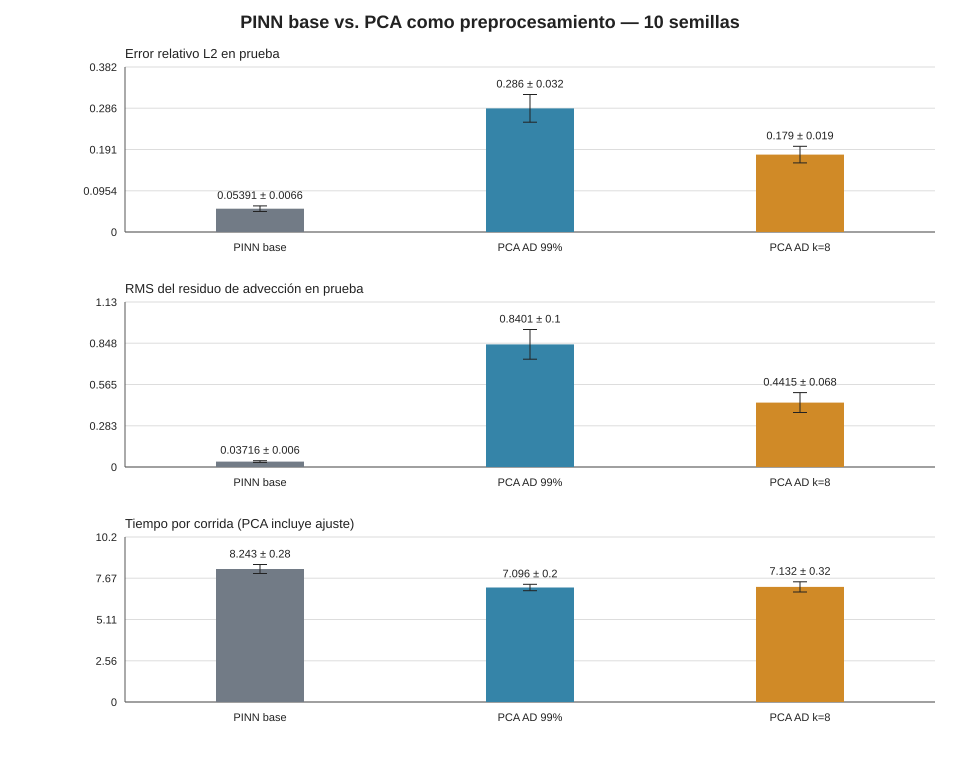

In [1]:
display(SVG(filename=str(RUN_DIR / "comparison.svg")))

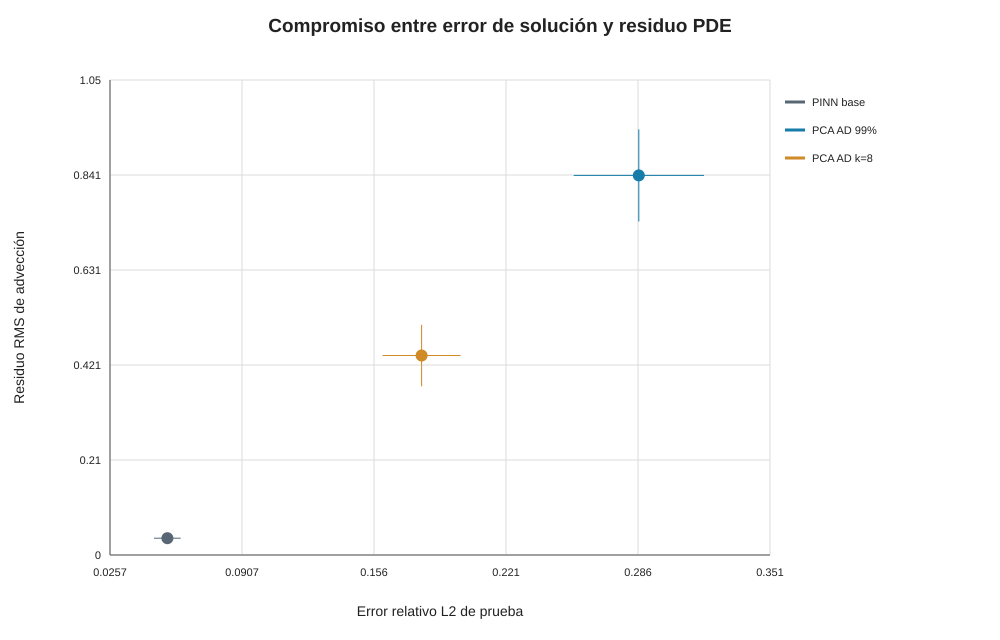

In [1]:
display(SVG(filename=str(RUN_DIR / "error_residual_tradeoff.svg")))

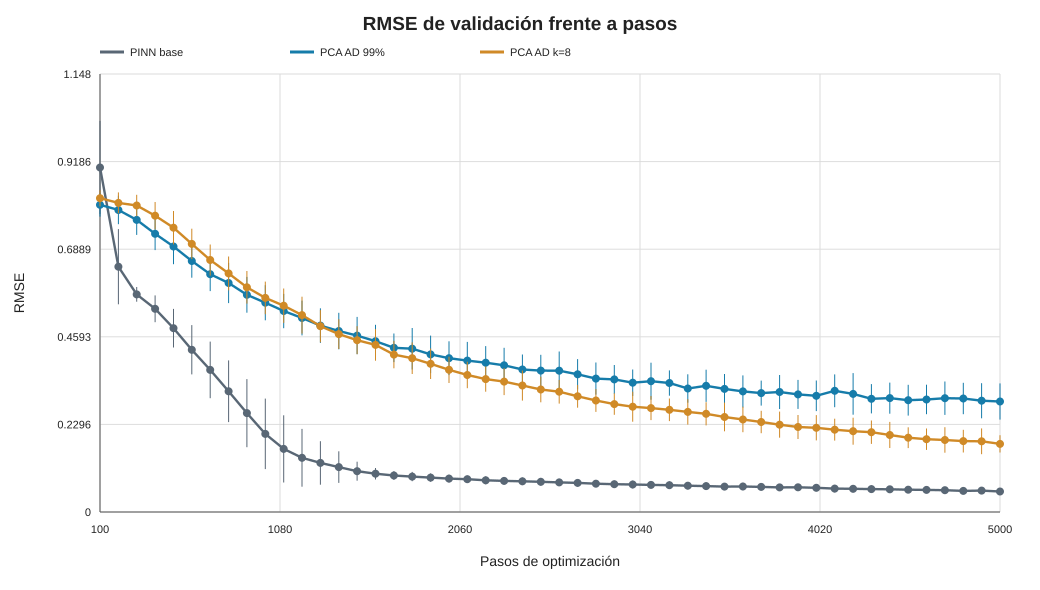

In [1]:
display(SVG(filename=str(RUN_DIR / "validation_rmse_vs_steps.svg")))

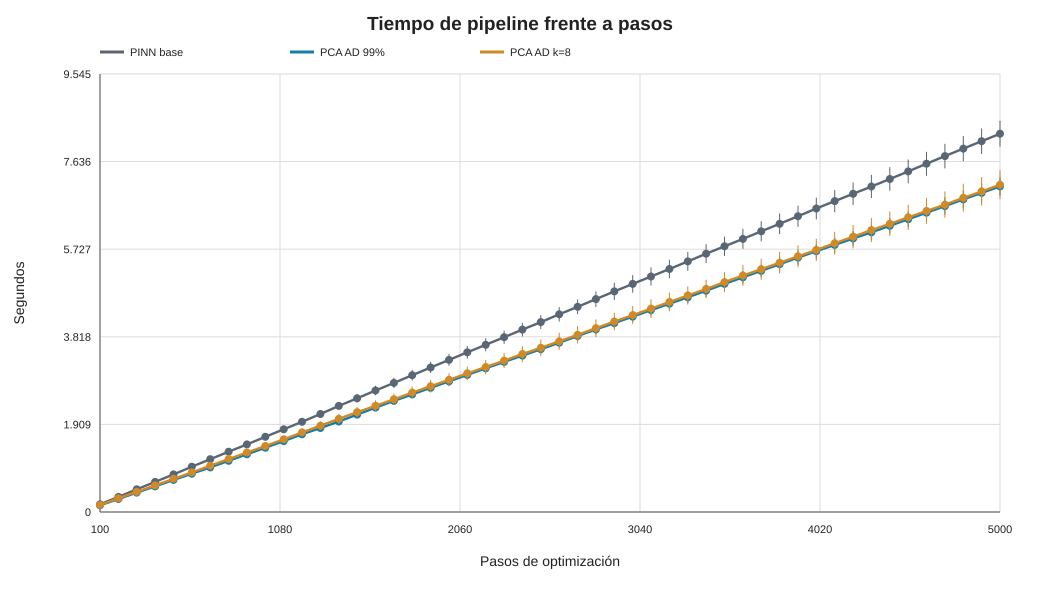

In [1]:
display(SVG(filename=str(RUN_DIR / "pipeline_time_vs_steps.svg")))

## Interpretación y cierre del benchmark

- La selección al 99% eligió `k=6`, pero su error L2 relativo (**0,2860**) y residuo PDE (**0,8401**) fueron mucho mayores que los de la PINN base (**0,0539** y **0,0372**).
- El `k=8` fijado de antemano también quedó por detrás de la base: error L2 **0,1790** y residuo PDE **0,4415**. Fue peor que la PINN base en ambas métricas en **10/10 semillas**.
- Ambas variantes PCA fueron más rápidas en el pipeline (alrededor de **7,1 s** frente a **8,24 s**) y su defecto periódico fue casi cero, pero esa reducción de tiempo no compensó el deterioro de la solución y del residuo físico.
- Por tanto, la mejora de `k=8` con la condición anterior de cuatro armónicos **no se replicó** en esta condición independiente. La selección por porcentaje de varianza tampoco identificó una dimensión que preservara el desempeño físico.

**Decisión:** damos por cerrado el benchmark de advección. La conclusión es condicionada: PCA puede reducir el tiempo y respetar periodicidad, pero su efecto sobre la precisión depende de la condición inicial; estos experimentos no respaldan una regla universal para elegir `k`. El siguiente trabajo debe pasar a otro tipo de dificultad de PINNs, como el escalamiento con la dimensión, sin seguir ajustando `k` para esta ecuación.

## Reproducibilidad

- Configuración: `configs/advection_six_harmonic_confirmation.json`
- Ejecutor: `scripts/run_advection_k_sweep.py`
- Resultados: `results/advection/base_vs_pca/six_harmonic_confirmation_10_seeds_5k_v1/`

```powershell
.venv-jax-latest\Scripts\python.exe scripts\run_advection_k_sweep.py --config configs\advection_six_harmonic_confirmation.json
```
